# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import AirbusAircraftDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv 

## Visualize images and objects witn bounding boxes

Total number of patches: 103


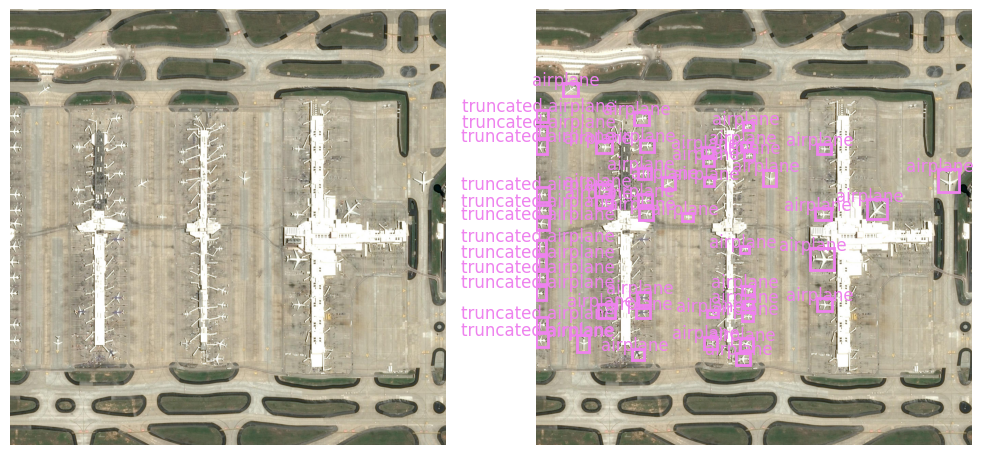

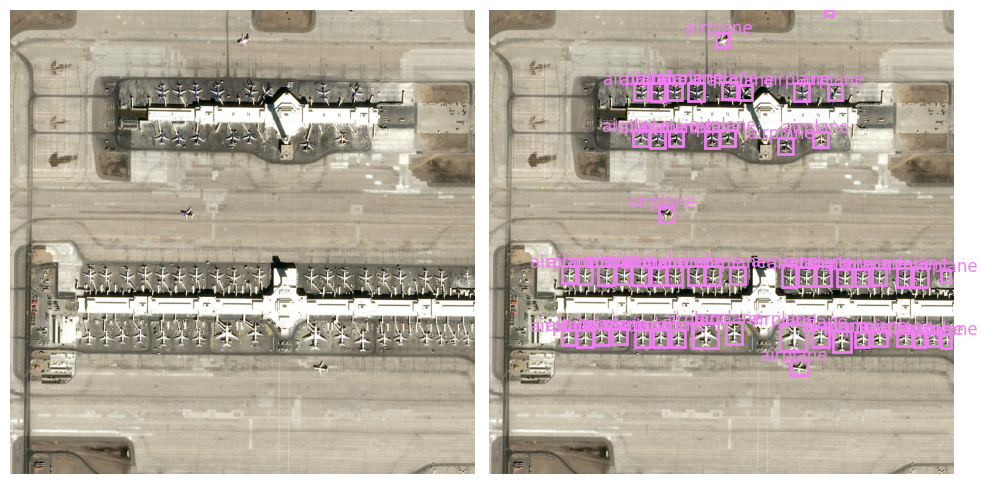

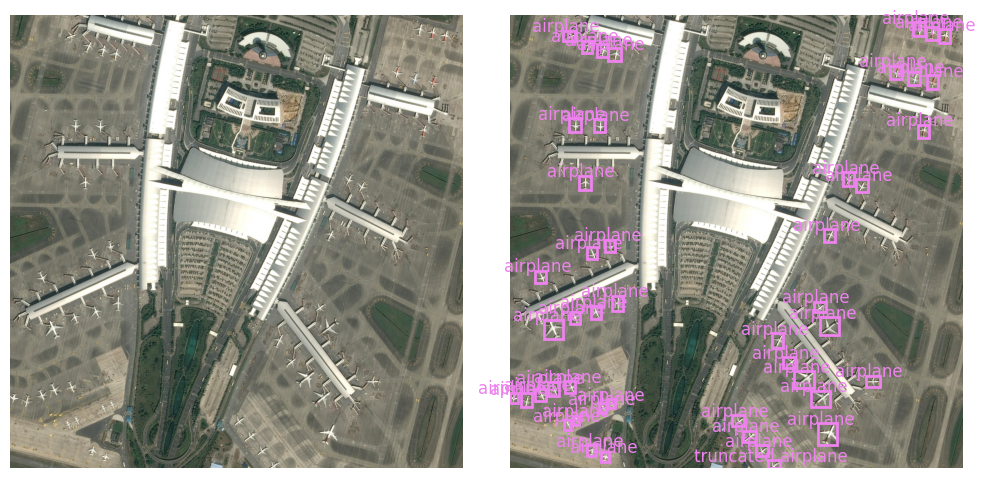

In [ ]:
dataset_config = {
    "data_dir": "./data/airbus_aircraft/images/",
    "annotation_dir": "./data/airbus_aircraft/annotations.csv",
}
dataset = AirbusAircraftDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

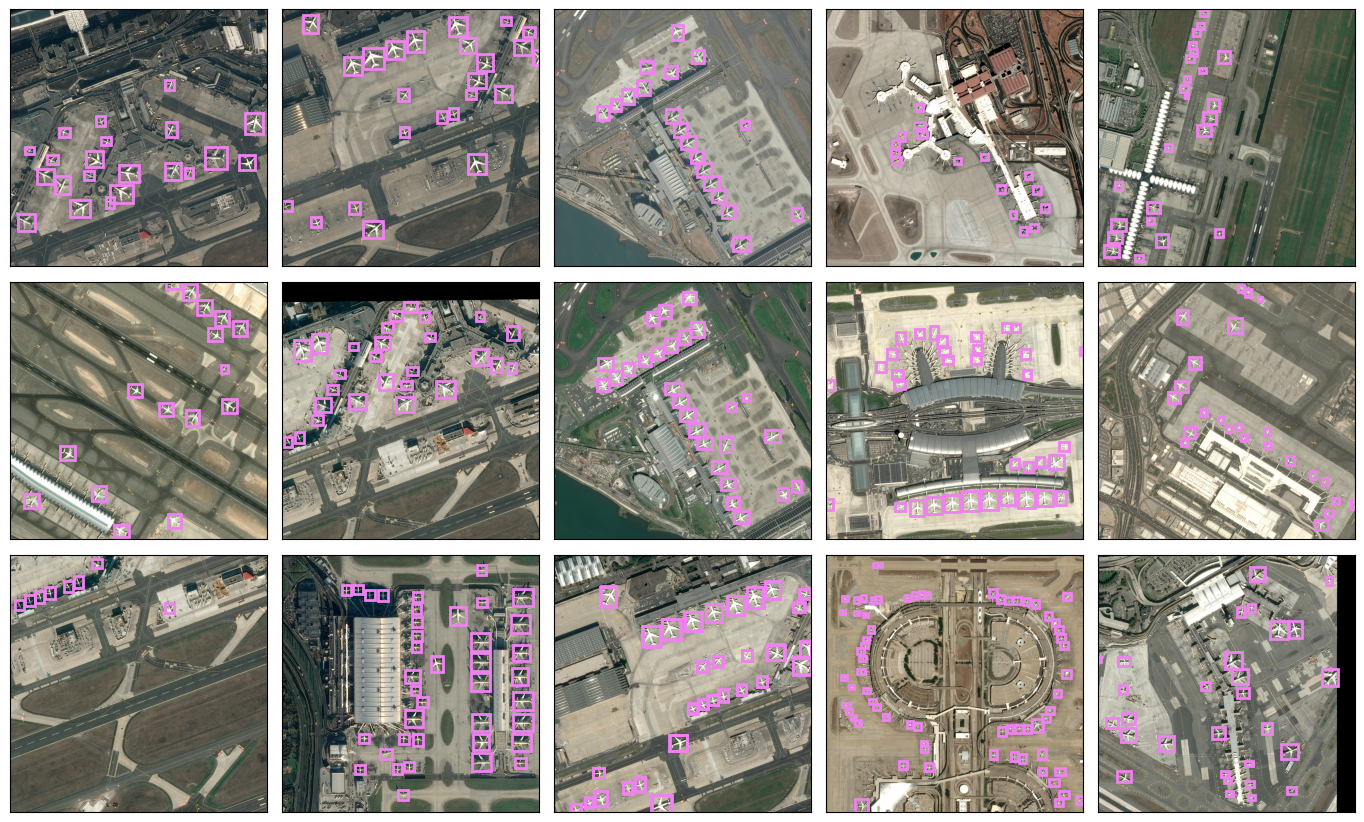

In [68]:
dataset.show_batch(15);

In [74]:
dataset.data_distribution_table()

,Label,Count
0,airplane,3316
1,truncated airplane,109


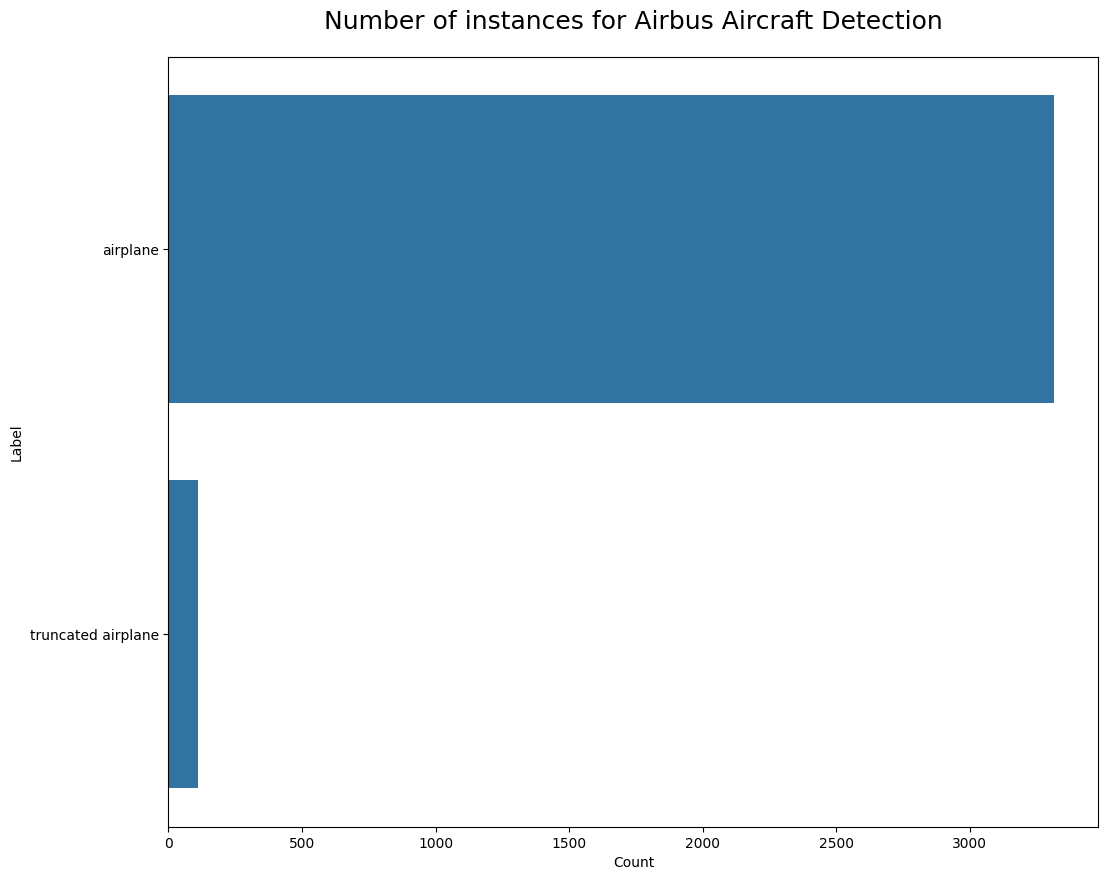

In [75]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/airbus_aircraft/images/",
    "annotation_dir": "./data/airbus_aircraft/annotations.csv",
    "csv_file": "./data/airbus_aircraft/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = AirbusAircraftDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 83


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/airbus_aircraft/experiments/"
model_config = {
    "num_classes": 3,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-21 12:59:57,470 INFO Starting training.
training: 100%|██████████| 11/11 [00:14<00:00,  1.30s/it]
2025-05-21 13:00:12,748 INFO epoch: 1, time: 14, loss:  1.84849
testing on train set: 100%|██████████| 11/11 [00:09<00:00,  1.20it/s]
2025-05-21 13:00:27,033 INFO map:0.20093697309494019, map_50:0.3981499671936035, map_75:0.1756771206855774, map_small:0.19941534101963043, map_medium:0.22869209945201874, map_large:-1.0, mar_1:0.0092537309974432, mar_10:0.08947761356830597, mar_100:0.24434702098369598, mar_small:0.2420724332332611, mar_medium:0.277179479598999, mar_large:-1.0, map_per_class:tensor(0.4019), tensor(0.), mar_100_per_class:tensor(0.4887), tensor(0.), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32)
training: 100%|██████████| 11/11 [00:14<00:00,  1.28s/it]
2025-05-21 13:00:41,133 INFO epoch: 2, time: 14, loss:  0.78844
testing on train set: 100%|██████████| 11/11 [00:09<00:00,  1.20it/s]
2025-05-21 13:00:53,296 INFO map:0.25688889622688293, map_50:0.4425

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/airbus_aircraft/images/",
    "annotation_dir": "./data/airbus_aircraft/annotations.csv",
    "csv_file": "./data/airbus_aircraft/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = AirbusAircraftDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/airbus_aircraft/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 10


2025-05-21 13:05:58,153 INFO Loading checkpoint /home/dragik/data/FAIR_EO/airbus_aircraft/experiments/checkpoint.pth.tar
2025-05-21 13:06:00,121 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/airbus_aircraft/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2/2 [00:03<00:00,  1.73s/it]


[{'map': 0.36286991834640503,
  'map_50': 0.5243436694145203,
  'map_75': 0.4677794277667999,
  'map_small': 0.3604773283004761,
  'map_medium': 0.7398133277893066,
  'map_large': -1.0,
  'mar_1': 0.04654403403401375,
  'mar_10': 0.1878669708967209,
  'mar_100': 0.40375325083732605,
  'mar_small': 0.40004390478134155,
  'mar_medium': 0.7782608866691589,
  'mar_large': -1.0,
  'map_per_class': [tensor(0.6327), tensor(0.0931)],
  'mar_100_per_class': [tensor(0.6853), tensor(0.1222)],
  'classes': [tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32)]}]

## Predictions

2025-05-21 13:06:23,218 INFO Loading checkpoint /home/dragik/data/FAIR_EO/airbus_aircraft/experiments/checkpoint.pth.tar
2025-05-21 13:06:25,077 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/airbus_aircraft/experiments/checkpoint.pth.tar at epoch 11


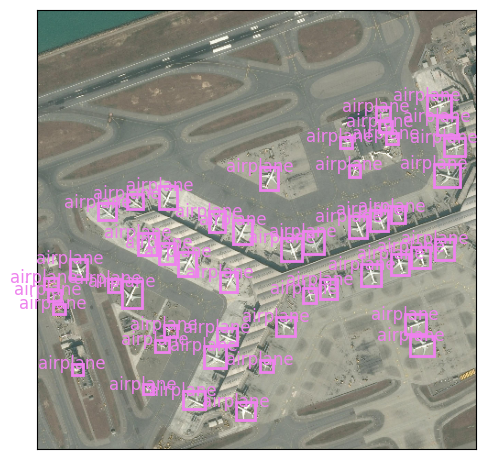

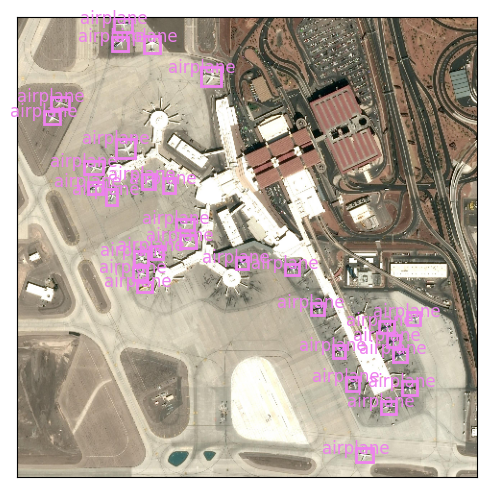

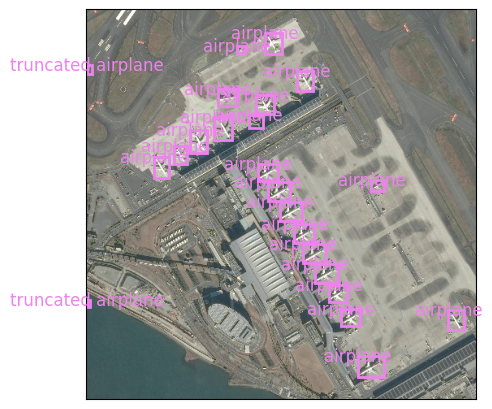

In [ ]:
model_config = {
    "num_classes": 3,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/airbus_aircraft/experiments/checkpoint.pth.tar"
labels = ["no-data","airplane", "truncated airplane"]
transform = Resize()
model.load_model(model_path)

csv_file = "./data/airbus_aircraft/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/airbus_aircraft/' + test_list[0])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/airbus_aircraft/' + test_list[5])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/airbus_aircraft/' + test_list[7])
fig = model.detect_objects(image, labels, transform)